# 01 · Data check: can we trust this experiment?

**Goal of this notebook:** before measuring whether the e-mails worked, make sure the data and the experiment
itself are sound. The later notebooks build on this.

We check, in order:
1. **The file is the original:** its checksum matches the published one.
2. **The data is clean:** correct columns and types, no missing values, and no impossible values
   (e.g. spend without a purchase).
3. **It matches the published numbers:** we reproduce the official visit, conversion and spend figures.
4. **The randomization worked:** the three groups are the expected sizes (*sample ratio mismatch* test)
   and contain the same kinds of customers (*covariate balance*).

If all four pass, any difference in outcomes between the groups can be attributed to the e-mail itself.
At the end we save a cleaned copy to `data/processed/`. The raw file is never changed.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use the shared helpers in src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.style import ARM_ORDER, ARM_LABELS, ARM_COLORS, set_style
from src.data import (RAW_PATH, CLEAN_PATH, RAW_SHA256, PRE_TREATMENT_NUMERIC, PRE_TREATMENT_CATEGORICAL,
                      OUTCOMES, HISTORY_SEGMENT_ORDER, sha256, load_raw, clean, load_clean)

ALPHA = 0.05   # significance level used throughout the project
SEED = 42      # fixed seed so any random step is reproducible
rng = np.random.default_rng(SEED)

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
FIG_DIR = ROOT / "figures"

## 1. Is this the original file?

A **SHA-256 checksum** works like a fingerprint for a file: change a single byte and the fingerprint changes
completely. If our file's fingerprint matches the one recorded in `data/README.md`, we know it is the exact
published dataset and has not been edited, truncated or corrupted.

In [2]:
actual = sha256(RAW_PATH)
print("expected:", RAW_SHA256)
print("actual:  ", actual)
assert actual == RAW_SHA256, "Raw file does not match the published checksum - stop and investigate."
print("OK: raw file is unchanged.")

expected: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece
actual:   0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece
OK: raw file is unchanged.


## 2. Structure and data quality

In [3]:
raw = load_raw()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

64,000 rows x 12 columns


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000


In [4]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
    "min": raw.min(numeric_only=True),
    "max": raw.max(numeric_only=True),
})
quality

,dtype,missing,unique_values,min,max
channel,str,0,3,NaN,NaN
conversion,int64,0,2,0.0000,1.0000
history,float64,0,34833,29.9900,"3,345.9300"
history_segment,str,0,7,NaN,NaN
mens,int64,0,2,0.0000,1.0000
newbie,int64,0,2,0.0000,1.0000
recency,int64,0,12,1.0000,12.0000
segment,str,0,3,NaN,NaN
spend,float64,0,429,0.0000,499.0000
visit,int64,0,2,0.0000,1.0000


In [5]:
for col in ["segment", "history_segment", "zip_code", "channel"]:
    print(raw[col].value_counts().sort_index().to_string(), "\n")

segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387 

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308 

zip_code
Rural         9563
Surburban    28776
Urban        25661 

channel
Multichannel     7762
Phone           28021
Web             28217 



**Logic checks.** Some combinations of values should be impossible, and finding them would point to a data error:
- someone with `conversion = 1` (bought) must have `spend > 0`, and vice versa;
- binary columns must only contain 0 and 1;
- `recency` must be within 1–12 months;
- the bucket in `history_segment` must agree with the actual dollar amount in `history`.

We count rows breaking each rule rather than silently dropping them, so any problem is visible.

We also look at a softer rule: a buyer should normally have visited the website (`visit = 1`). This one is not
guaranteed, because a customer could buy by phone after reading the e-mail, so we report it but do not treat
it as an error.

In [6]:
binary_cols = ["mens", "womens", "newbie", "visit", "conversion"]
checks = {
    "converted but spend = 0": ((raw.conversion == 1) & (raw.spend <= 0)).sum(),
    "spend > 0 but not converted": ((raw.conversion == 0) & (raw.spend > 0)).sum(),
    "negative spend": (raw.spend < 0).sum(),
    "non-binary value in a 0/1 column": (~raw[binary_cols].isin([0, 1])).sum().sum(),
    "recency outside 1-12": (~raw.recency.between(1, 12)).sum(),
    "unknown history_segment label": (~raw.history_segment.isin(HISTORY_SEGMENT_ORDER)).sum(),
    "(soft) converted without a website visit": ((raw.conversion == 1) & (raw.visit == 0)).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
converted but spend = 0,0
spend > 0 but not converted,0
negative spend,0
non-binary value in a 0/1 column,0
recency outside 1-12,0
unknown history_segment label,0
(soft) converted without a website visit,0


In [7]:
# Does each history bucket's real dollar range fit its label?
raw.groupby("history_segment")["history"].agg(["min", "max", "count"]).reindex(HISTORY_SEGMENT_ORDER)

,min,max,count
history_segment,,,
1) $0 - $100,29.9900,99.9900,22970
2) $100 - $200,100.0000,199.9800,14254
3) $200 - $350,200.0000,349.9600,12289
4) $350 - $500,350.0100,499.9500,6409
5) $500 - $750,500.0000,749.7900,4911
"6) $750 - $1,000",750.0100,999.7500,1859
"7) $1,000 +","1,000.1500","3,345.9300",1308


In [8]:
print("exact duplicate rows:", raw.duplicated().sum())

exact duplicate rows: 6562


*Duplicate rows:* there is no customer ID in this dataset, so two different customers with identical attributes
and outcomes (very common when most outcomes are zero) look like "duplicates". We report the count for
transparency, but these are not errors and we keep every row.

## 3. Does it match the published figures?

Kevin Hillstrom published the headline results when he released the data. Reproducing them exactly confirms that
we read and interpret the columns the same way he did.

In [9]:
summary = (raw.groupby("segment")
              .agg(customers=("visit", "size"), visit_rate=("visit", "mean"),
                   conversion_rate=("conversion", "mean"), spend_per_customer=("spend", "mean"))
              .reindex(ARM_ORDER))

published = pd.DataFrame(
    {"visit_rate": [0.1062, 0.1828, 0.1514],
     "conversion_rate": [0.0057, 0.0125, 0.0088],
     "spend_per_customer": [0.65, 1.42, 1.08]},
    index=ARM_ORDER)

comparison = summary.join(published.add_suffix("_published"))
comparison

,customers,visit_rate,conversion_rate,spend_per_customer,visit_rate_published,conversion_rate_published,spend_per_customer_published
segment,,,,,,,
No E-Mail,21306,0.1062,0.0057,0.6528,0.1062,0.0057,0.6500
Mens E-Mail,21307,0.1828,0.0125,1.4226,0.1828,0.0125,1.4200
Womens E-Mail,21387,0.1514,0.0088,1.0772,0.1514,0.0088,1.0800


In [10]:
# Published figures are rounded (rates to 0.01 pp, spend to 1 cent), so compare within that rounding.
assert np.allclose(summary.visit_rate, published.visit_rate, atol=0.00005)
assert np.allclose(summary.conversion_rate, published.conversion_rate, atol=0.00005)
assert np.allclose(summary.spend_per_customer, published.spend_per_customer, atol=0.005)
print("OK: matches the published validation table.")

OK: matches the published validation table.


## 4. Did the randomization work?

Random assignment is what turns this into a fair comparison: if a coin decided who got which e-mail, then the groups
differ *only* in the e-mail they received. Two things can break that in practice:

### 4a. Sample ratio mismatch (SRM)

The experiment was designed as a three-way split, so each group should hold about one third of the 64,000
customers. Small random deviations are normal, but a large one usually means something went wrong, such as a
bug in assignment or e-mails that bounced and were dropped from one group.

We use a **chi-square goodness-of-fit test**. It asks: *if the true split were exactly 1/3 each, how surprising
would the group sizes we observe be?*
- A large p-value means the sizes are consistent with a fair split.
- A tiny p-value (the industry convention for SRM is p < 0.001, stricter than our usual 0.05 because a false
  alarm here would throw away the whole experiment) means we should not trust the results.

In [11]:
observed = raw["segment"].value_counts().reindex(ARM_ORDER)
expected = np.full(len(observed), observed.sum() / len(observed))
chi2, p_srm = stats.chisquare(observed, expected)

srm = pd.DataFrame({"observed": observed, "expected": expected.round(1),
                    "share": (observed / observed.sum()).round(4)})
display(srm)
print(f"chi-square = {chi2:.3f}, p-value = {p_srm:.3f}")
print("SRM detected!" if p_srm < 0.001 else "No sample ratio mismatch: group sizes are consistent with a 1/3 split.")

,observed,expected,share
segment,,,
No E-Mail,21306,"21,333.3000",0.3329
Mens E-Mail,21307,"21,333.3000",0.3329
Womens E-Mail,21387,"21,333.3000",0.3342


chi-square = 0.203, p-value = 0.904
No sample ratio mismatch: group sizes are consistent with a 1/3 split.


### 4b. Covariate balance

Next we check that each group contains the same *kind* of customers **before** the e-mail was sent: same recency,
past spend, men's/women's buyers, new customers, location and purchase channel. These "pre-treatment" variables
cannot have been affected by the e-mail, so any big difference would come from flawed randomization.

**Why standardized mean differences (SMD) and not just p-values?** With 21,000+ customers per group, a statistical
test will flag even a trivially small difference as "significant". The SMD instead measures *how big* the
difference is, in standard-deviation units:

$$\text{SMD} = \frac{\bar{x}_{\text{email}} - \bar{x}_{\text{control}}}{\sqrt{(s^2_{\text{email}} + s^2_{\text{control}})/2}}$$

The widely used rule of thumb (from the clinical-trials and causal-inference literature) is that **|SMD| < 0.1**
counts as well balanced. Categorical variables (e.g. `channel`) are split into one 0/1 column per category so each
category's share can be compared.

In [12]:
def smd(x_treat, x_ctrl):
    pooled_sd = np.sqrt((x_treat.var() + x_ctrl.var()) / 2)
    return (x_treat.mean() - x_ctrl.mean()) / pooled_sd if pooled_sd > 0 else 0.0

# Numeric + binary covariates as-is, categoricals as one dummy column per category
covars = pd.concat(
    [raw[PRE_TREATMENT_NUMERIC],
     pd.get_dummies(raw[PRE_TREATMENT_CATEGORICAL], prefix_sep=": ", dtype=float)],
    axis=1)

ctrl = covars[raw.segment == "No E-Mail"]
balance = pd.DataFrame({
    arm: {c: smd(covars.loc[raw.segment == arm, c], ctrl[c]) for c in covars.columns}
    for arm in ["Mens E-Mail", "Womens E-Mail"]
})
balance.columns = ["SMD: men's vs control", "SMD: women's vs control"]
print(f"largest |SMD| = {balance.abs().max().max():.4f}  (threshold 0.1)")
balance

largest |SMD| = 0.0164  (threshold 0.1)


,SMD: men's vs control,SMD: women's vs control
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
history_segment: 1) $0 - $100,0.0109,-0.0007
history_segment: 2) $100 - $200,-0.0164,-0.0143
history_segment: 3) $200 - $350,0.0055,0.0114
history_segment: 4) $350 - $500,-0.0043,0.0087
history_segment: 5) $500 - $750,-0.0097,0.0006


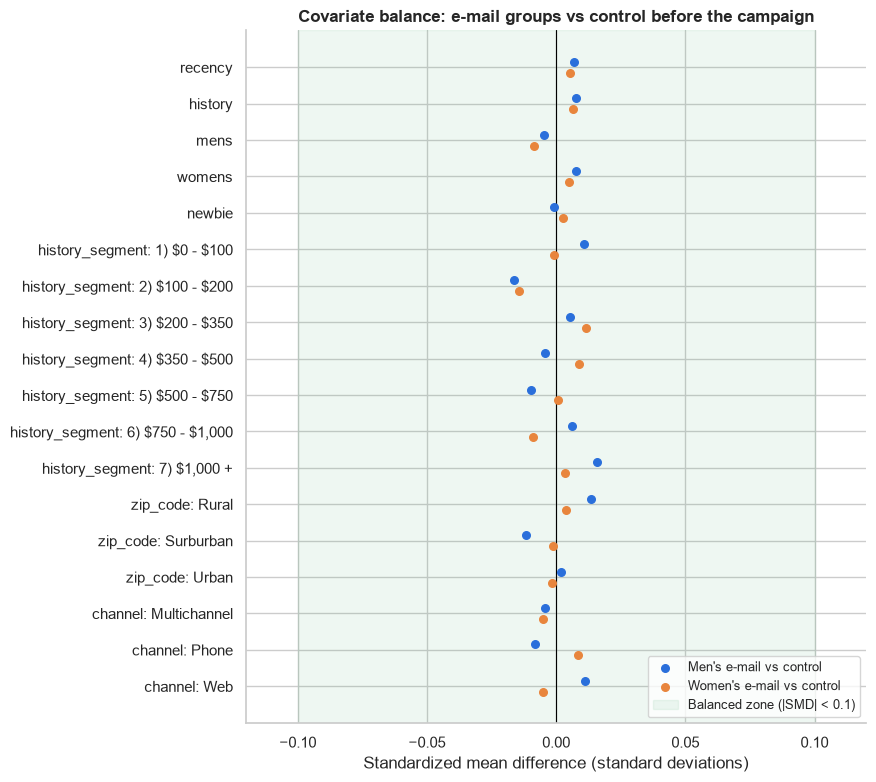

In [13]:
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(balance))
for (col, arm), offset in zip([("SMD: men's vs control", "Mens E-Mail"),
                               ("SMD: women's vs control", "Womens E-Mail")], [-0.15, 0.15]):
    ax.scatter(balance[col], y + offset, color=ARM_COLORS[arm], label=ARM_LABELS[arm] + " vs control", s=30, zorder=3)
ax.axvspan(-0.1, 0.1, color="#2e9e5b", alpha=0.08, label="Balanced zone (|SMD| < 0.1)")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y, [label.replace("$", r"\$") for label in balance.index])  # stop "$" being read as math markup
ax.invert_yaxis()
ax.set_xlim(-0.12, 0.12)
ax.set_xlabel("Standardized mean difference (standard deviations)")
ax.set_title("Covariate balance: e-mail groups vs control before the campaign")
ax.legend(loc="lower right", fontsize=9)
fig.savefig(FIG_DIR / "01_covariate_balance.png")
plt.show()

**Formal tests as a cross-check.** For completeness we also run a significance test per variable across all three
groups:
- **Chi-square test of independence** for categorical and 0/1 variables: is the category mix the same in every group?
- **Kruskal–Wallis test** for `recency` and `history`. It compares the groups without assuming normally
  distributed values, which matters because past spend (`history`) is strongly right-skewed.

Keep in mind that with 8 tests, the chance that at least one shows p < 0.05 *purely by luck* is about 34%, even
with perfect randomization. So one borderline p-value would not worry us; the SMDs above are the main evidence.

In [14]:
rows = []
for col in ["recency", "history"]:
    groups = [raw.loc[raw.segment == a, col] for a in ARM_ORDER]
    rows.append((col, "Kruskal-Wallis", stats.kruskal(*groups).pvalue))
for col in ["mens", "womens", "newbie", *PRE_TREATMENT_CATEGORICAL]:
    rows.append((col, "Chi-square", stats.chi2_contingency(pd.crosstab(raw[col], raw.segment)).pvalue))

balance_tests = pd.DataFrame(rows, columns=["variable", "test", "p_value"]).set_index("variable")
balance_tests["below 0.05"] = balance_tests.p_value < ALPHA
balance_tests

,test,p_value,below 0.05
variable,,,
recency,Kruskal-Wallis,0.7941,False
history,Kruskal-Wallis,0.6669,False
mens,Chi-square,0.6717,False
womens,Chi-square,0.7289,False
newbie,Chi-square,0.9339,False
history_segment,Chi-square,0.3580,False
zip_code,Chi-square,0.5795,False
channel,Chi-square,0.4580,False


## 5. A first look at the outcomes' shape

We don't test any effects here, but one property of the data decides which methods the next notebook should use:
**spend is extremely concentrated**. Most customers spend nothing in the two weeks.

In [15]:
buyers = raw[raw.spend > 0]
print(f"buyers: {len(buyers):,} of {len(raw):,} customers ({len(buyers) / len(raw):.2%})")
buyers.spend.describe()

buyers: 578 of 64,000 customers (0.90%)


count   578.0000
mean    116.3635
std     107.8715
min      29.9900
25%      32.2725
50%      80.7950
75%     153.3500
max     499.0000
Name: spend, dtype: float64

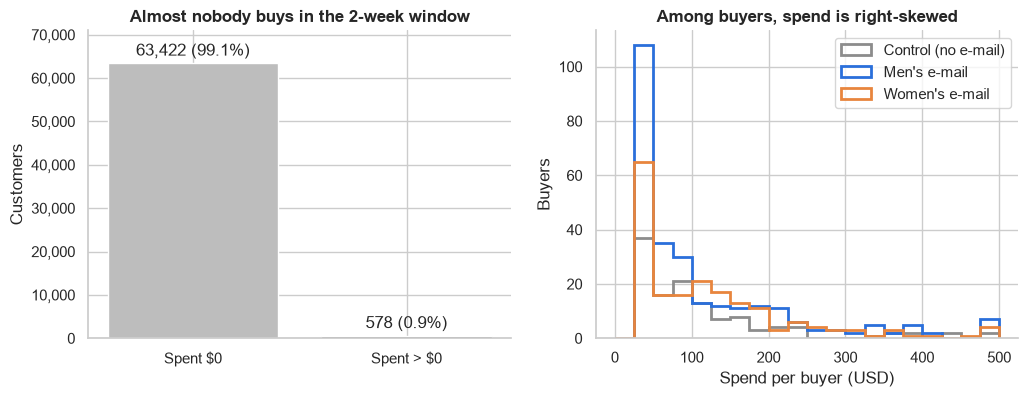

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = [(raw.spend == 0).sum(), (raw.spend > 0).sum()]
bars = axes[0].bar([r"Spent \$0", r"Spent > \$0"], counts, color=["#bdbdbd", "#4c4c4c"])
axes[0].bar_label(bars, labels=[f"{n:,} ({n / len(raw):.1%})" for n in counts], padding=3)
axes[0].set_ylabel("Customers")
axes[0].set_ylim(0, max(counts) * 1.12)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title("Almost nobody buys in the 2-week window")
for arm in ARM_ORDER:
    axes[1].hist(buyers.loc[buyers.segment == arm, "spend"], bins=np.arange(0, 525, 25),
                 histtype="step", lw=2, color=ARM_COLORS[arm], label=ARM_LABELS[arm])
axes[1].set_xlabel("Spend per buyer (USD)")
axes[1].set_ylabel("Buyers")
axes[1].set_title("Among buyers, spend is right-skewed")
axes[1].legend()
fig.savefig(FIG_DIR / "01_spend_distribution.png")
plt.show()

**What this means for the analysis:** average spend per customer is driven by a few hundred buyers, and is far from
the bell-shaped distribution a plain t-test assumes. In notebook 02 we will therefore measure the uncertainty in
spend with a **bootstrap**: we resample the customers thousands of times and see how much the average moves.
This does not rely on any distribution assumption. Welch's t-test serves as a cross-check.

## 6. Save the cleaned dataset

The raw data turned out to be clean, so "cleaning" here means small, documented conveniences for later notebooks:
- fix the typo `Surburban` → `Suburban` in `zip_code`;
- add `treatment` (`control` / `mens` / `womens`) as a short code for the arm;
- add `emailed` (1 if the customer received any e-mail, 0 for control);
- store the categories in a logical order (e.g. history buckets from lowest to highest).

No rows are removed. The result is written to `data/processed/`. Later notebooks load it with `load_clean()`, which
restores the category ordering that a CSV file cannot store.

In [17]:
df = clean(raw)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN_PATH, index=False)

# Round-trip check: the saved file reloads to the same data, and the raw file is still untouched.
reloaded = load_clean()
pd.testing.assert_frame_equal(reloaded, df, check_categorical=True)
assert sha256(RAW_PATH) == RAW_SHA256
print(f"saved {len(df):,} rows to {CLEAN_PATH.relative_to(ROOT)}")
df.dtypes.to_frame("dtype")

saved 64,000 rows to data\processed\hillstrom_clean.csv


,dtype
recency,int64
history_segment,category
history,float64
mens,int64
womens,int64
zip_code,category
newbie,int64
channel,category
segment,category
visit,int64


## 7. Summary: the experiment is trustworthy

| Check | Result | Verdict |
|---|---|---|
| File integrity | SHA-256 matches the published checksum | ✅ original data |
| Data quality | 64,000 rows, 12 columns, 0 missing values, 0 rule violations (spend/conversion consistent, binaries 0/1, recency 1–12, history buckets match dollar amounts) | ✅ clean |
| Published figures | Visit, conversion and spend per customer reproduce the official table for all three groups | ✅ interpreted correctly |
| Sample ratio | 21,306 / 21,307 / 21,387 customers; chi-square p = 0.90 | ✅ no SRM |
| Covariate balance | Largest \|SMD\| = 0.016 across 18 comparisons (threshold 0.1); none of the 8 formal tests below 0.05 | ✅ groups are alike |

**Bottom line:** the three groups are the same kinds of customers in the same proportions, so differences in
visits, purchases and spend after the campaign can be credited to the e-mail itself.

**Things to carry forward into the analysis:**
- **Spend is rare and skewed:** only 578 buyers (0.9%). Among them, the median order is about \$81, but a few go up
  to \$499. Use bootstrap confidence intervals for spend (notebook 02).
- **Every buyer also visited the website,** so the funnel is clean: e-mail → visit → purchase. We can report both
  steps.
- **The 6,562 "duplicate" rows** are identical-looking customers (no ID column, mostly zero outcomes), not data
  errors, and are kept.
- **Segment sizes for targeting:** some groups are small. For example, only 1,308 customers spent \$1,000+ last
  year (~436 per arm), so effects within such segments will be estimated with wide uncertainty (notebook 03).

**Output:** `data/processed/hillstrom_clean.csv` (load with `src.data.load_clean()`), plus
`figures/01_covariate_balance.png` and `figures/01_spend_distribution.png`.

**Next:** `02_ab_test.ipynb`, which measures the effect of each e-mail on visits, conversions and spend.